# 03 Model experiments

LightGBM v1 under GroupKFold, nested isotonic calibration, baselines, reliability, SHAP, and error rates by income and race (Gate 2). The saved model is trained by `python scripts/train_model.py`. This notebook reads those artifacts.

In [1]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from lll import MODEL_DIR, REPO_ROOT

FIG = REPO_ROOT / "docs" / "figures"
m = json.loads((MODEL_DIR / "metrics_v1.json").read_text())
err = pd.read_csv(MODEL_DIR / "error_rates_v1.csv")
print(f"n = {m['n']:,}")
print(f"PR-AUC {m['pr_auc']:.3f}  ROC-AUC {m['roc_auc']:.3f}  Brier {m['brier']:.3f}  ECE {m['ece']:.3f}")
print(f"balanced accuracy {m['balanced_accuracy']:.3f}  false non-lead {m['false_nonlead_rate']:.3f}")

n = 215,692
PR-AUC 0.960  ROC-AUC 0.959  Brier 0.060  ECE 0.001
balanced accuracy 0.916  false non-lead 0.029


## Baselines

In [2]:
rows = {
    "LightGBM v1": m,
    "Pre-1986 rule": m["baselines"]["pre1986"],
    "Block majority": m["baselines"]["block_majority"],
}
cols = ["pr_auc", "roc_auc", "balanced_accuracy", "brier", "ece", "false_nonlead_rate"]
tab = pd.DataFrame(rows).T[cols]
display(tab.round(3))
print(f"PR-AUC lift vs block {m['pr_auc_lift_vs_block']:+.3f} (need +0.05)")
print(f"BA lift vs pre-1986 {m['ba_lift_vs_pre1986']:+.3f} (need +0.05)")
print(f"random-fold PR-AUC {m['pr_auc_random_fold']:.3f} vs grouped {m['pr_auc']:.3f}")

,pr_auc,roc_auc,balanced_accuracy,brier,ece,false_nonlead_rate
LightGBM v1,0.959632,0.959123,0.915954,0.059971,0.000701,0.029088
Pre-1986 rule,0.697356,0.683033,0.683033,0.258155,0.258155,0.002664
Block majority,0.602316,0.532675,0.532675,0.381034,0.381034,0.006171


PR-AUC lift vs block +0.357 (need +0.05)
BA lift vs pre-1986 +0.233 (need +0.05)
random-fold PR-AUC 0.962 vs grouped 0.960


## Utility-side Unknown slice\n\nMost lookups have an unknown utility side too. PR-AUC is still high because 91% of those known customer sides are lead or GRR; ROC-AUC and balanced accuracy show the model is conservative, not a sharp non-lead detector.

In [3]:
print(f"n={m['n_utility_unknown']:,}  prevalence {m['prevalence_utility_unknown']:.1%}")
print(f"PR-AUC {m['pr_auc_utility_unknown']:.3f} vs block {m['pr_auc_block_utility_unknown']:.3f}")
print(f"ROC-AUC {m['roc_auc_utility_unknown']:.3f}  BA {m['balanced_accuracy_utility_unknown']:.3f} "
      f"vs pre-1986 {m['ba_pre1986_utility_unknown']:.3f}")

n=117,946  prevalence 91.1%
PR-AUC 0.965 vs block 0.910
ROC-AUC 0.764  BA 0.547 vs pre-1986 0.503


## Reliability, confusion, SHAP

**Calibrated OOF reliability (10 equal-width bins).**

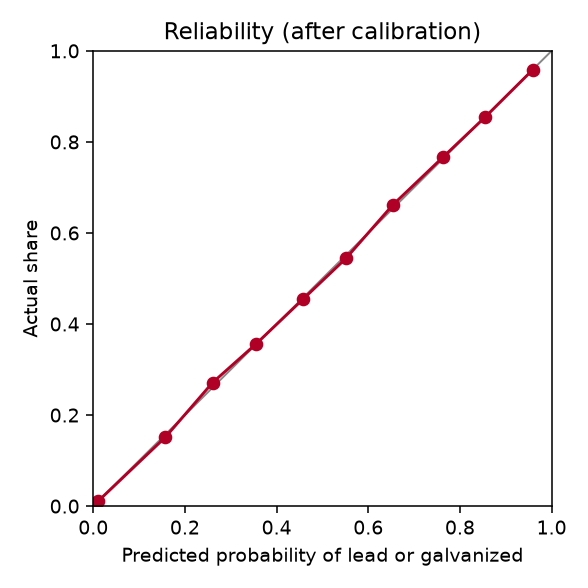

**OOF confusion matrix at 50%.**

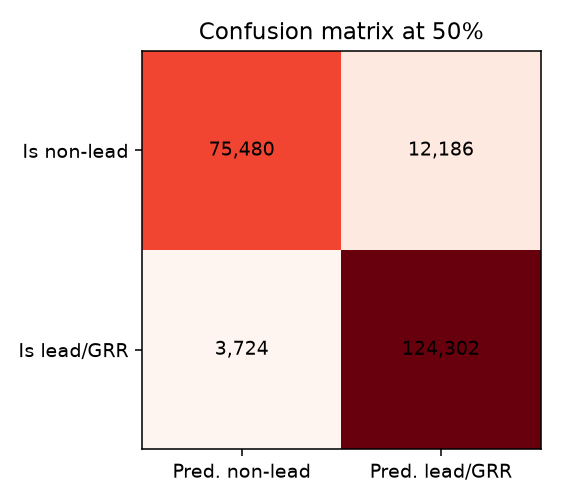

**Mean |SHAP| on a 2,000-row training sample.**

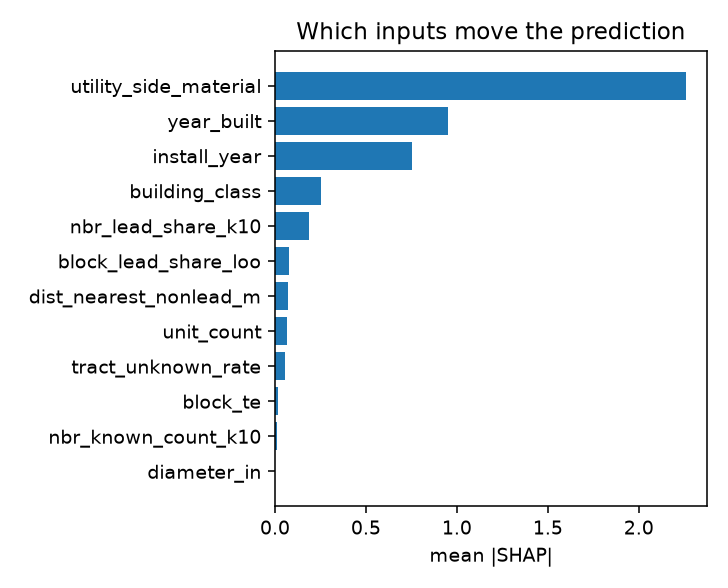

In [4]:
for name, cap in [
    ("reliability_v1.png", "Calibrated OOF reliability (10 equal-width bins)."),
    ("confusion_v1.png", "OOF confusion matrix at 50%."),
    ("shap_summary_v1.png", "Mean |SHAP| on a 2,000-row training sample."),
]:
    display(Markdown(f"**{cap}**"))
    display(Image(filename=str(FIG / name)))

## Error rates by income quartile and majority group\n\nFalse non-lead is the dangerous error. It is not higher in Q1 or majority-Black/Latino tracts than in Q4 or majority-White tracts, so v1 does not raise the non-lead confidence bar.

In [5]:
show = err[["grouping", "group", "n", "rate_lead", "pr_auc", "false_nonlead_rate", "false_lead_rate"]]
display(show.round(3))

,grouping,group,n,rate_lead,pr_auc,false_nonlead_rate,false_lead_rate
0,income_quartile,Q1 lowest income,38412,0.636,0.942,0.031,0.204
1,income_quartile,Q2,50314,0.699,0.965,0.027,0.188
2,income_quartile,Q3,55645,0.654,0.966,0.024,0.160
3,income_quartile,Q4 highest income,62070,0.485,0.958,0.034,0.099
4,majority_group,Asian,1764,0.291,0.876,0.043,0.071
5,majority_group,Black,66472,0.708,0.962,0.020,0.216
6,majority_group,Latino,40400,0.709,0.965,0.034,0.200
7,majority_group,No majority,33786,0.534,0.947,0.031,0.135
8,majority_group,White,66189,0.499,0.959,0.034,0.100
